# Cap. 5 · AR(1), vida media y densidad espectral
*Proyecto DAT 262 · Monitor de estrés cambiario y monetario de Bolivia*

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from stress_monitor import data, stationarity as stat, markov as mk, forecasting as fc, gap as gp, simulation as sim, demo
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": .3})
m = data.load_monthly(); d = data.load_daily_key()
print("Datos mensuales:", m.index.min().date(), "→", m.index.max().date(), f"({len(m)} meses)")

Datos mensuales: 1989-01-31 → 2026-10-31 (454 meses)


**AR(1):** $G_t=c+\phi G_{t-1}+\varepsilon_t$. Media de largo plazo $c/(1-\phi)$ y **vida media** $\ln(0{,}5)/\ln\phi$ (tiempo para que se cierre la mitad de una desviación). Densidad espectral: $f(\omega)$ estimada con el periodograma.

Picos: [2.8, 11.9, 2.8] meses


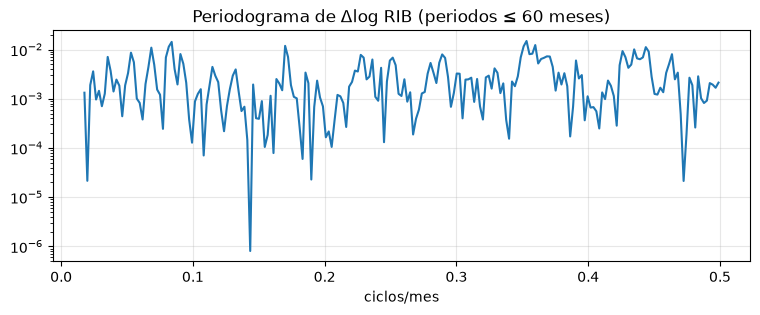

In [2]:
dl = np.log(m['rib']).diff().dropna()
sp = stat.periodogram(dl, min_freq=1/60)
fig, ax = plt.subplots(figsize=(9, 3)); ax.semilogy(sp['f'], sp['pxx']); ax.set_xlabel('ciclos/mes'); ax.set_title('Periodograma de Δlog RIB (periodos ≤ 60 meses)')
print('Picos:', [round(p['periodo_meses'], 1) for p in sp['picos']], 'meses')

### Brecha oficial–paralelo
Si hay historial P2P real se usa; si no, se muestra con **datos SIMULADOS (DEMO)** solo para ilustrar el método.

In [3]:
col, pdf = data.load_p2p(); g = data.build_gap(m, d, col, pdf); demo_flag = False
if len(g) < gp.MIN_OBS:
    g = demo.synthetic_gap(m, d); demo_flag = True
    print('⚠️ DATOS DEMO SIMULADOS (no reales)')
r = gp.ar1_gap(g['brecha_pct'][g.index >= data.FECHA_FLEXIBLE])
print({k: (round(v, 3) if isinstance(v, float) else v) for k, v in r.items() if k in ('n', 'phi', 'vida_media', 'media_larga')})

⚠️ DATOS DEMO SIMULADOS (no reales)
{'n': 131, 'phi': 0.864, 'vida_media': 4.749, 'media_larga': 1.423}


Text(0.5, 1.0, 'Brecha (%) — DEMO simulada')

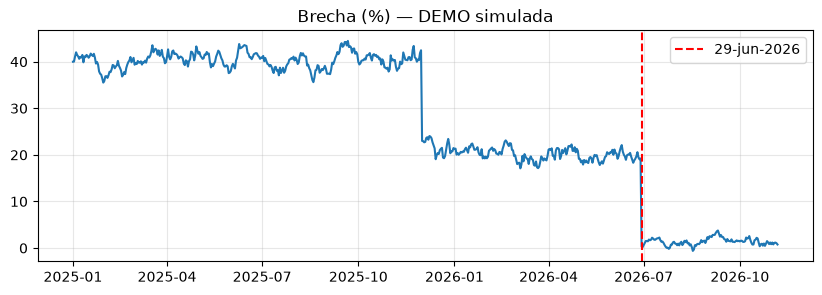

In [4]:
x = g['brecha_pct']
fig, ax = plt.subplots(figsize=(10, 3)); ax.plot(x); ax.axvline(data.FECHA_FLEXIBLE, c='r', ls='--', label='29-jun-2026'); ax.legend()
ax.set_title('Brecha (%)' + (' — DEMO simulada' if demo_flag else ''))